## Compare SHAM Results with Favole Figure 7

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import sham
import sample
import stats
import halotools
from halotools.mock_observables import return_xyz_formatted_array
from halotools.mock_observables import tpcf_jackknife

TNG_H = 0.6774

In [2]:
# Read in TNG100 Data
file_number = 447
directory = 'data/subhalo_data' 
check_subhalo_flag = True
subhalo_data = data.import_subhalo(file_number, directory, check_subhalo_flag)

100%|█████████████████████████████████████████████████████████████████████████████████| 448/448 [01:13<00:00,  6.08it/s]


In [3]:
# Read in TNG100-Dark Data
file_number = 63
directory = 'data/dmo_data' 
dmo_data = data.import_dmo(file_number, directory)

100%|███████████████████████████████████████████████████████████████████████████████████| 64/64 [00:09<00:00,  6.49it/s]


In [4]:
# Execute SHAM
dmo_data['StellarMassPred'] = sham.sham(dmo_data['SubhaloMass'], subhalo_data['StellarMass'])
dmo_data['logStellarMassPred'] = np.log10(dmo_data['StellarMassPred'])

In [5]:
# Define Stellar Mass bin
stellar_mass_true1 = sample.mass_sample(subhalo_data, 'logStellarMass', 8.75, 9.3)
stellar_mass_true2 = sample.mass_sample(subhalo_data, 'logStellarMass', 9.3, 10.0)
stellar_mass_true3 = sample.mass_sample(subhalo_data, 'logStellarMass', 10.0, 12.5)

In [6]:
stellar_mass_pred1= sample.mass_sample(dmo_data, 'logStellarMassPred', 8.75, 9.3)
stellar_mass_pred2= sample.mass_sample(dmo_data, 'logStellarMassPred', 9.3, 10.0)
stellar_mass_pred3= sample.mass_sample(dmo_data, 'logStellarMassPred', 10.0, 12.5)

In [8]:
# Compute 2pt correlation functions truth
Lbox = 110.7*TNG_H
rbins = np.logspace(np.log10(.1), np.log10(24.9), 16)
rbin_centers = (rbins[1:] + rbins[:-1])/2.

pos_true1 = return_xyz_formatted_array(stellar_mass_true1['x'], stellar_mass_true1['y'], stellar_mass_true1['z'])
pos_pred1 = return_xyz_formatted_array(stellar_mass_pred1['x'], stellar_mass_pred1['y'], stellar_mass_pred1['z'])

randoms_true1 = stats.generate_randoms(Lbox, 30000)
randoms_pred1 = stats.generate_randoms(Lbox, 30000)

xi_true1, cov_true1 = tpcf_jackknife(pos_true1, randoms_true1, rbins, Nsub = 3, period = Lbox, num_threads = 'max')
xi_pred1, cov_pred1 = tpcf_jackknife(pos_pred1, randoms_pred1, rbins, Nsub = 3, period = Lbox, num_threads = 'max')

# Second mass bin
pos_true2 = return_xyz_formatted_array(stellar_mass_true2['x'], stellar_mass_true2['y'], stellar_mass_true2['z'])
pos_pred2 = return_xyz_formatted_array(stellar_mass_pred2['x'], stellar_mass_pred2['y'], stellar_mass_pred2['z'])

randoms_true2 = stats.generate_randoms(Lbox, 30000)
randoms_pred2 = stats.generate_randoms(Lbox, 30000)

xi_true2, cov_true2 = tpcf_jackknife(pos_true2, randoms_true2, rbins, Nsub = 3, period = Lbox, num_threads = 'max')
xi_pred2, cov_pred2 = tpcf_jackknife(pos_pred2, randoms_pred2, rbins, Nsub = 3, period = Lbox, num_threads = 'max')

# Third mass bin
pos_true3 = return_xyz_formatted_array(stellar_mass_true3['x'], stellar_mass_true3['y'], stellar_mass_true3['z'])
pos_pred3 = return_xyz_formatted_array(stellar_mass_pred3['x'], stellar_mass_pred3['y'], stellar_mass_pred3['z'])

randoms_true3 = stats.generate_randoms(Lbox, 30000)
randoms_pred3 = stats.generate_randoms(Lbox, 30000)

xi_true3, cov_true3 = tpcf_jackknife(pos_true3, randoms_true3, rbins, Nsub = 3, period = Lbox, num_threads = 'max')
xi_pred3, cov_pred3 = tpcf_jackknife(pos_pred3, randoms_pred3, rbins, Nsub = 3, period = Lbox, num_threads = 'max')

In [9]:
# Read in Favole CSV
favole1 = pd.read_csv('favole_tpcf_8.75_9.3.csv', header = None, names = ["r", "xi"])
favole2 = pd.read_csv('favole_sham_8.75_9.3.csv', header = None, names = ["r", "xi"])

favole3 = pd.read_csv('favole_tpcf_9.3_10.0.csv', header = None, names = ["r", "xi"])
favole4 = pd.read_csv('favole_sham_9.3_10.0.csv', header = None, names = ["r", "xi"])

favole5 = pd.read_csv('favole_tpcf_10.0_12.5.csv', header = None, names = ["r", "xi"])
favole6 = pd.read_csv('favole_sham_10.0_12.5.csv', header = None, names = ["r", "xi"])

In [10]:
errors_true1 = stats.compute_tpcf_jackknife_errors(cov_true1) *3
errors_pred1 = stats.compute_tpcf_jackknife_errors(cov_pred1) *3

errors_true2 = stats.compute_tpcf_jackknife_errors(cov_true2) *3
errors_pred2 = stats.compute_tpcf_jackknife_errors(cov_pred2) *3

errors_true3 = stats.compute_tpcf_jackknife_errors(cov_true3) *3
errors_pred3 = stats.compute_tpcf_jackknife_errors(cov_pred3) *3

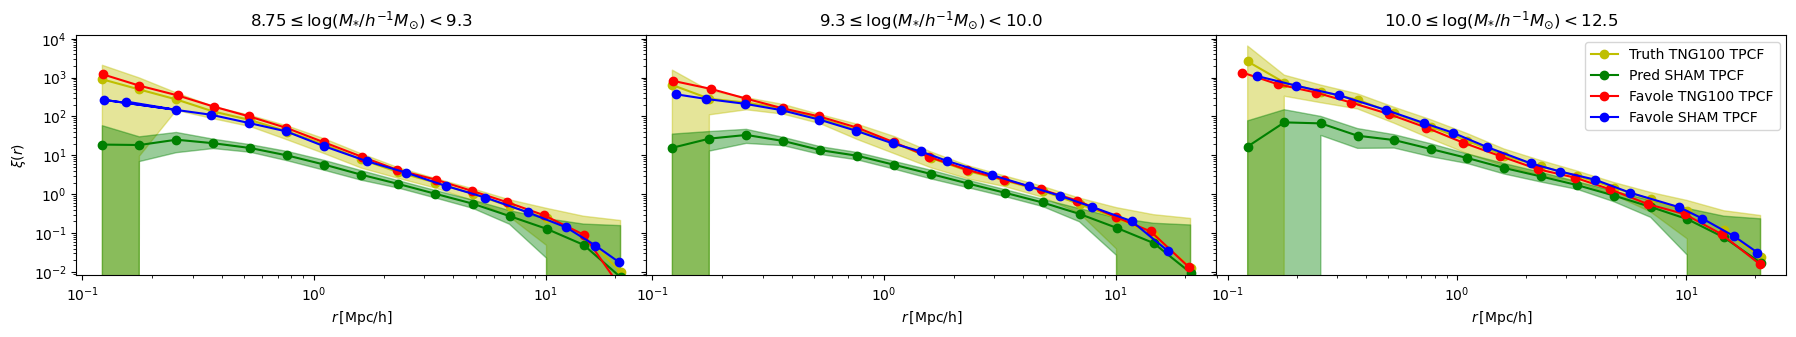

In [27]:
import matplotlib.pyplot as plt

# Create a 1x3 grid of subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(19, 3), sharey=True)

# Plot for the first set
axes[0].plot(rbin_centers, xi_true1,'y-o', label = 'Truth TNG100 TPCF')
axes[0].plot(rbin_centers, xi_pred1,'g-o', label = 'Pred SHAM TPCF')
axes[0].plot(favole1["r"], favole1["xi"], 'r-o', label = "Favole TNG100 TPCF")
axes[0].plot(favole2["r"], favole2["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[0].fill_between(rbin_centers, xi_true1-errors_true1, xi_true1+errors_true1, alpha=0.4, color = 'y')
axes[0].fill_between(rbin_centers, xi_pred1-errors_pred1, xi_pred1+errors_pred1, alpha=0.4, color = 'g')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title(r'$8.75 \leq \log(M_{*}/h^{-1}M_{\odot}) < 9.3$')
axes[0].set_xlabel(r'$r \, \rm{[Mpc/h]}$')
axes[0].set_ylabel(r'$\xi(r)$')

# Plot for the second set
axes[1].plot(rbin_centers, xi_true2,'y-o', label = 'Truth TNG100 TPCF')
axes[1].plot(rbin_centers, xi_pred2,'g-o', label = 'Pred SHAM TPCF')
axes[1].plot(favole3["r"], favole3["xi"], 'r-o', label = "Favole TNG100 TPCF")
axes[1].plot(favole4["r"], favole4["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[1].fill_between(rbin_centers, xi_true2-errors_true2, xi_true2+errors_true2, alpha=0.4, color = 'y')
axes[1].fill_between(rbin_centers, xi_pred2-errors_pred2, xi_pred2+errors_pred2, alpha=0.4, color = 'g')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title(r'$9.3 \leq \log(M_{*}/h^{-1}M_{\odot}) < 10.0$')
axes[1].set_xlabel(r'$r \, \rm{[Mpc/h]}$')

# Plot for the third set
axes[2].plot(rbin_centers, xi_true3,'y-o', label = 'Truth TNG100 TPCF')
axes[2].plot(rbin_centers, xi_pred3,'g-o', label = 'Pred SHAM TPCF')
axes[2].plot(favole5["r"], favole5["xi"], 'r-o', label = "Favole TNG100 TPCF")
axes[2].plot(favole6["r"], favole6["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[2].fill_between(rbin_centers, xi_true3-errors_true3, xi_true3+errors_true3, alpha=0.4, color = 'y')
axes[2].fill_between(rbin_centers, xi_pred3-errors_pred3, xi_pred3+errors_pred3, alpha=0.4, color = 'g')
axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].set_title(r'$10.0 \leq \log(M_{*}/h^{-1}M_{\odot}) < 12.5$')
axes[2].set_xlabel(r'$r \, \rm{[Mpc/h]}$')
axes[2].legend()

# Adjust layout to remove space between subplots
plt.subplots_adjust(wspace=0, left=0.05, right=0.95, bottom=0.1, top=0.9)

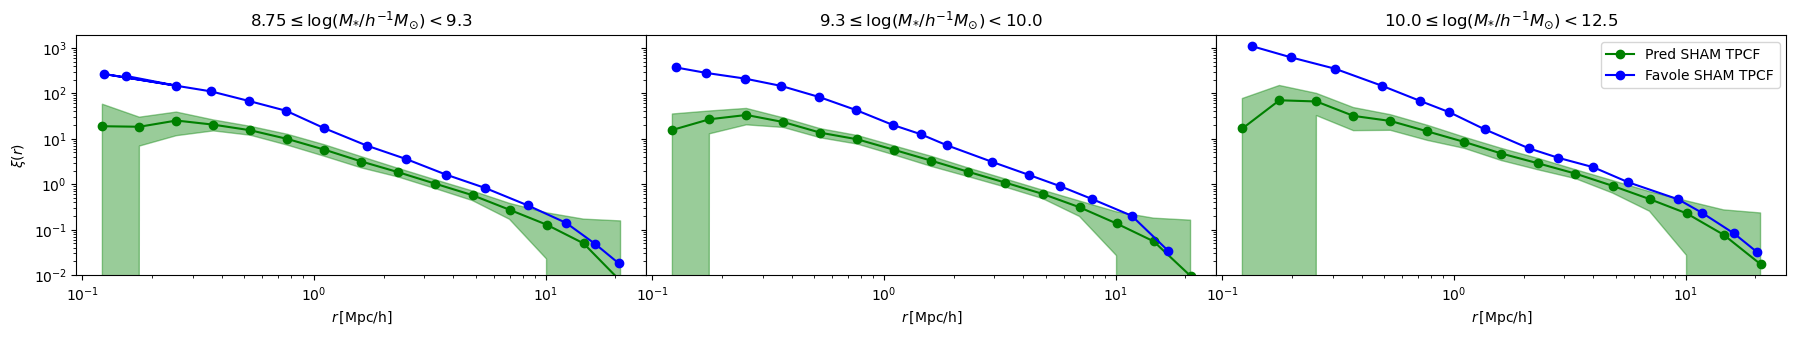

In [28]:
import matplotlib.pyplot as plt

# Create a 1x3 grid of subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(19, 3), sharey=True)

# Plot for the first set
axes[0].plot(rbin_centers, xi_pred1,'g-o', label = 'Pred SHAM TPCF')
axes[0].plot(favole2["r"], favole2["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[0].fill_between(rbin_centers, xi_pred1-errors_pred1, xi_pred1+errors_pred1, alpha=0.4, color = 'g')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title(r'$8.75 \leq \log(M_{*}/h^{-1}M_{\odot}) < 9.3$')
axes[0].set_xlabel(r'$r \, \rm{[Mpc/h]}$')
axes[0].set_ylabel(r'$\xi(r)$')

# Plot for the second set
axes[1].plot(rbin_centers, xi_pred2,'g-o', label = 'Pred SHAM TPCF')
axes[1].plot(favole4["r"], favole4["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[1].fill_between(rbin_centers, xi_pred2-errors_pred2, xi_pred2+errors_pred2, alpha=0.4, color = 'g')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title(r'$9.3 \leq \log(M_{*}/h^{-1}M_{\odot}) < 10.0$')
axes[1].set_xlabel(r'$r \, \rm{[Mpc/h]}$')

# Plot for the third set
axes[2].plot(rbin_centers, xi_pred3,'g-o', label = 'Pred SHAM TPCF')
axes[2].plot(favole6["r"], favole6["xi"], 'b-o', label = "Favole SHAM TPCF")
axes[2].fill_between(rbin_centers, xi_pred3-errors_pred3, xi_pred3+errors_pred3, alpha=0.4, color = 'g')
axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].set_title(r'$10.0 \leq \log(M_{*}/h^{-1}M_{\odot}) < 12.5$')
axes[2].set_xlabel(r'$r \, \rm{[Mpc/h]}$')
axes[2].legend()

# Adjust layout to remove space between subplots
plt.subplots_adjust(wspace=0, left=0.05, right=0.95, bottom=0.1, top=0.9)